In [10]:
import matplotlib.pyplot as plt
import numpy as np
from itertools import product
import pandas as pd
from scipy.linalg import expm
import math
from itertools import product


In [11]:


# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


# Testing first order perturbation theory

In [12]:
Q=4
# --- Reduced exact Q=4 ---
def r_inf_exact_Q4(L, tau, nu):
    Ks= [(k1, k2, k3) for k1, k2, k3 in product(range(L+1), repeat=3) if k1 + k2 + k3 <= L]
    print(len(Ks))
    m = np.array([(
    math.comb(L, k1)
    * math.comb(L - k1, k2)
    * math.comb(L - k1 - k2, k3)
) for (k1,k2,k3) in Ks])
    A0 = (nu / Q**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()
    A2=A0.copy()
    A3=A0.copy()
    A0 += np.diag([k0 - nu for (k0,k1,k2) in Ks])
    A1 += np.diag([k1 - nu for (k0,k1,k2) in Ks])
    A2 += np.diag([k2 - nu for (k0,k1,k2) in Ks])
    A3 += np.diag([L-k1-k2-k3 - nu for (k1,k2,k3) in Ks])
    M = expm(A3 * tau) @expm(A2 * tau) @expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return np.log(lam_max) / (4 * tau)

[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 0, 4), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 0), (0, 2, 1), (0, 2, 2), (0, 3, 0), (0, 3, 1), (0, 4, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 0, 3), (1, 1, 0), (1, 1, 1), (1, 1, 2), (1, 2, 0), (1, 2, 1), (1, 3, 0), (2, 0, 0), (2, 0, 1), (2, 0, 2), (2, 1, 0), (2, 1, 1), (2, 2, 0), (3, 0, 0), (3, 0, 1), (3, 1, 0), (4, 0, 0)]
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 0, 4), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 0), (0, 2, 1), (0, 2, 2), (0, 3, 0), (0, 3, 1), (0, 4, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 0, 3), (1, 1, 0), (1, 1, 1), (1, 1, 2), (1, 2, 0), (1, 2, 1), (1, 3, 0), (2, 0, 0), (2, 0, 1), (2, 0, 2), (2, 1, 0), (2, 1, 1), (2, 2, 0), (3, 0, 0), (3, 0, 1), (3, 1, 0), (4, 0, 0)]
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 0, 4), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 0), (0, 2, 1), (0, 2, 2), (0, 3, 0), (0, 3, 1), (0, 4, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 0, 3), (1, 1, 0), (1, 1, 

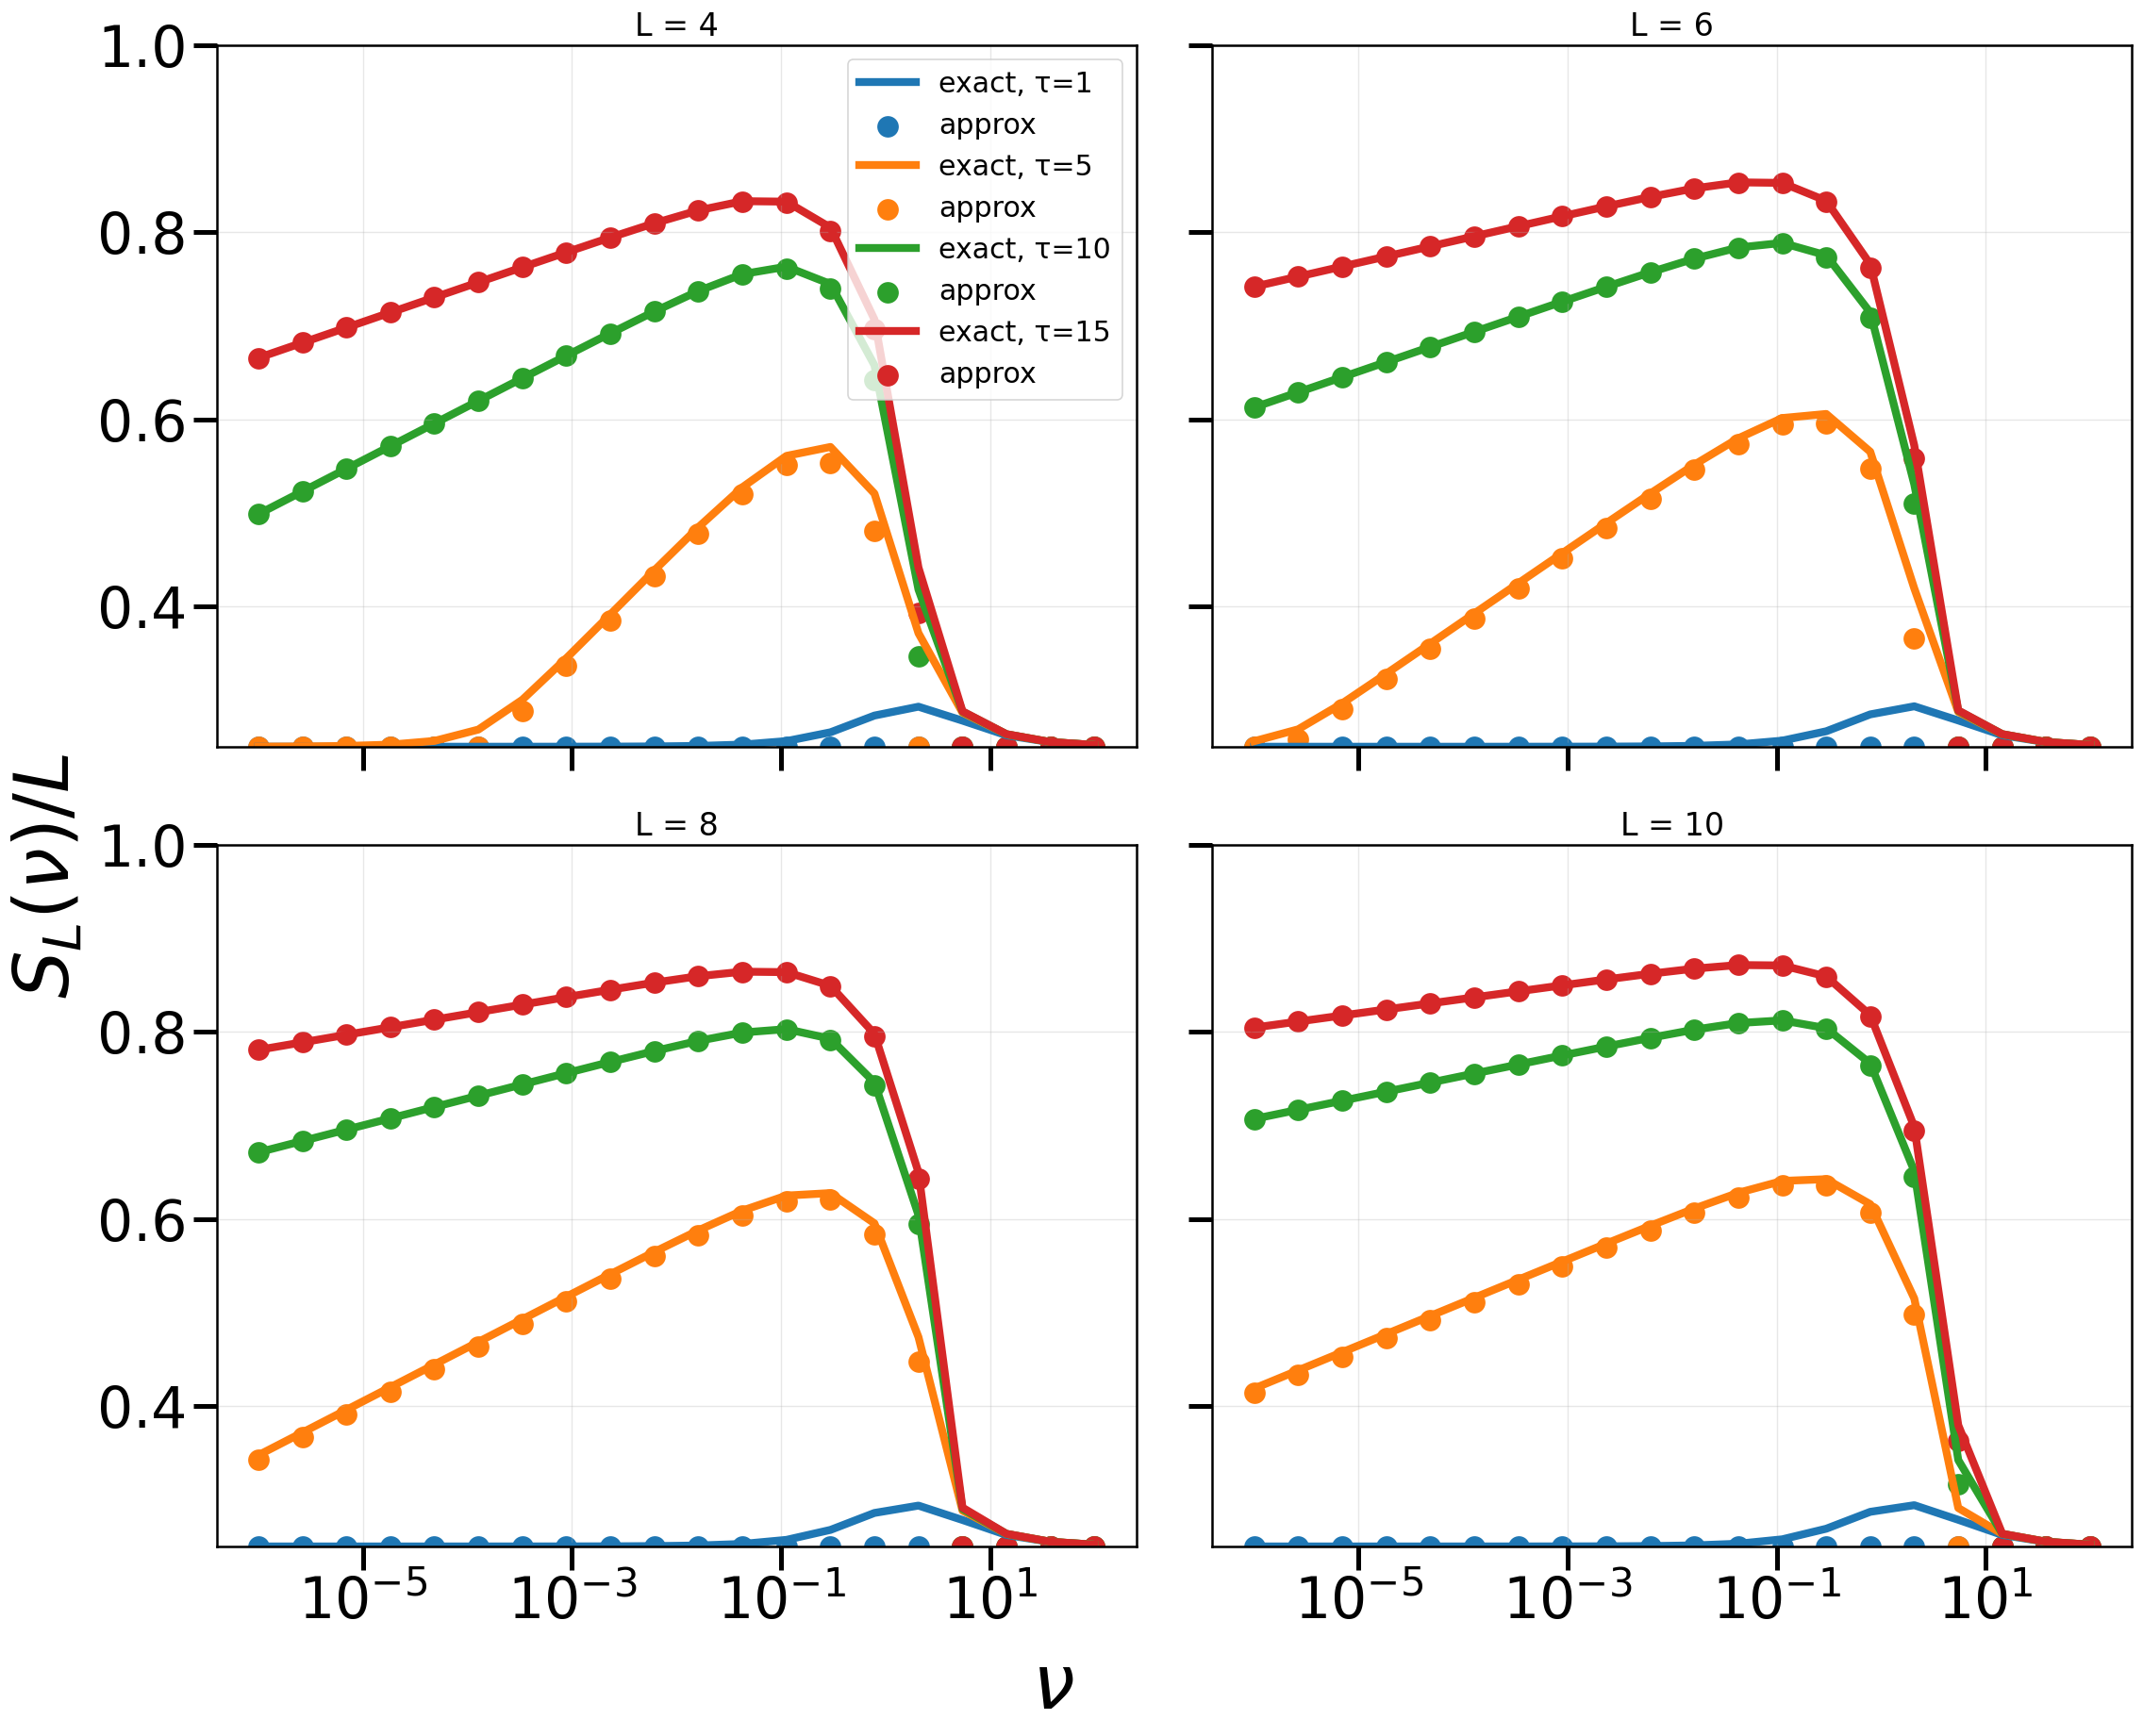

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import math

Ls = [4,6,8,10]
taus = [1,5, 10, 15]
nu_list = np.logspace(-6, 2, 20)

fig, axes = plt.subplots(2, 2, figsize=(20, 16), sharex=True, sharey=True)
axes = axes.flatten()

for ax, L in zip(axes, Ls):
    for tau in taus:
        exact = [r_inf_exact_Q4(L, tau, nu)/L for nu in nu_list]
        approx = [max(L/Q,L-nu*(1-Q**(-L))+np.log(2*nu/Q**L/L)/tau)/L for nu in nu_list]

        ax.plot(nu_list, exact, label=f"exact, τ={tau}")
        ax.scatter(nu_list, approx, s=160, label=f"approx")

    ax.set_title(f"L = {L}")
    ax.set_xscale("log")
    ax.set_ylim(1/Q, 1)
    ax.grid(True, alpha=0.3)

# Legend only in the first panel
axes[0].legend(fontsize=18)

# Common labels
fig.text(0.5, 0.04, r"$\nu$", ha="center",fontsize=48)
fig.text(0.04, 0.5, r"$S_L(\nu) / L$", va="center", rotation="vertical",fontsize=48)

plt.tight_layout(rect=[0.06, 0.06, 1, 1])
plt.savefig('S_L_Q4.png')
plt.savefig('S_L_Q4.svg')
plt.show()


# Check subspace 

[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 2, 0), (0, 2, 1), (0, 3, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 1, 0), (1, 1, 1), (1, 2, 0), (2, 0, 0), (2, 0, 1), (2, 1, 0), (3, 0, 0)]
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 2, 0), (0, 2, 1), (0, 3, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 1, 0), (1, 1, 1), (1, 2, 0), (2, 0, 0), (2, 0, 1), (2, 1, 0), (3, 0, 0)]
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 2, 0), (0, 2, 1), (0, 3, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 1, 0), (1, 1, 1), (1, 2, 0), (2, 0, 0), (2, 0, 1), (2, 1, 0), (3, 0, 0)]
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 2, 0), (0, 2, 1), (0, 3, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 1, 0), (1, 1, 1), (1, 2, 0), (2, 0, 0), (2, 0, 1), (2, 1, 0), (3, 0, 0)]
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 2, 0), (0, 2, 1), (0, 3, 0), (1, 0

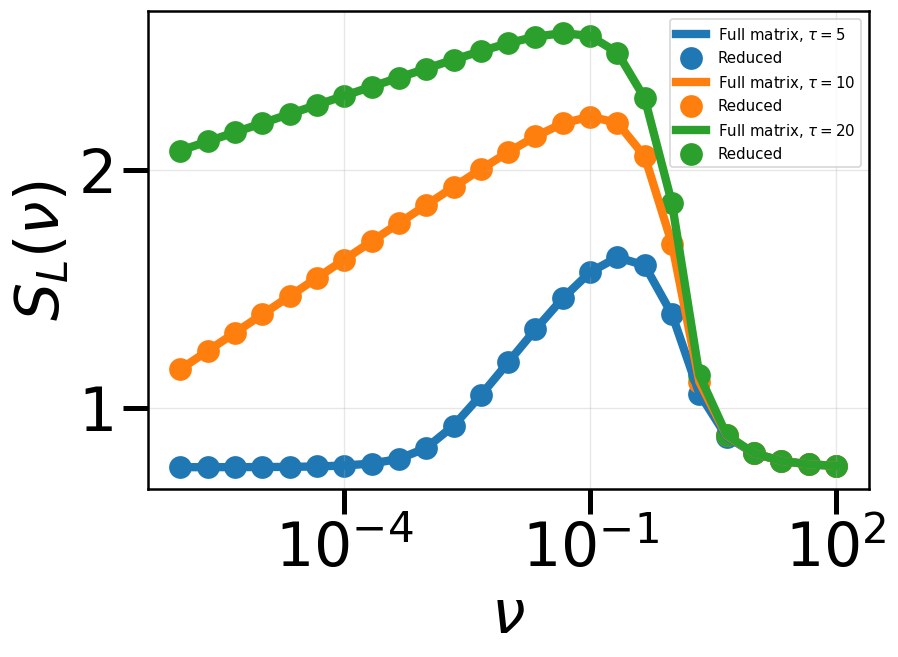

In [14]:


Q = 4
L = 3
taus = [5, 10, 20]
nu_list = np.logspace(-6, 2, 25)

# --- Exact A3 generator ---
def A3_matrix(Hvec, mu, Q):
    N = Q**L
    H3 = (Hvec[:, None, None]
        + Hvec[None, :, None]
        + Hvec[None, None, :]).reshape(N)

    A = np.full((N, N), mu / N)
    np.fill_diagonal(A, H3 - mu * (N-1)/N)
    return A

# --- Reduced exact Q=4 ---
def r_inf_exact_Q4(L, tau, nu):
    Ks= [(k1, k2, k3) for k1, k2, k3 in product(range(L+1), repeat=3) if k1 + k2 + k3 <= L]
    print(Ks)
    m = np.array([(
    math.comb(L, k1)
    * math.comb(L - k1, k2)
    * math.comb(L - k1 - k2, k3)
) for (k1,k2,k3) in Ks])
    A0 = (nu / Q**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()
    A2=A0.copy()
    A3=A0.copy()

    A0 += np.diag([k0 - nu for (k0,k1,k2) in Ks])
    A1 += np.diag([k1 - nu for (k0,k1,k2) in Ks])
    A2 += np.diag([k2 - nu for (k0,k1,k2) in Ks])
    A3 += np.diag([L-k1-k2-k3 - nu for (k1,k2,k3) in Ks])
    M = expm(A3 * tau) @expm(A2 * tau) @expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return np.log(lam_max) / (4 * tau)

# --- Build A3 matrices (fixed structure, varying nu) ---
Hvec1 = np.array([1.0, 0.0,0.0,0.0])
Hvec2 = np.array([0.0, 1.0,0.0,0.0])
Hvec3 = np.array([0.0, 0.0,1.0,0.0])
Hvec4 = np.array([0.0, 0.0,0.0,1.0])
# --- Plot ---


for tau in taus:
    r_A3 = []
    r_Q4 = []

    for nu in nu_list:
        A3 = A3_matrix(Hvec1, nu, Q)
        A3_bis = A3_matrix(Hvec2, nu, Q)
        A3_ter = A3_matrix(Hvec3, nu, Q)
        A3_qua = A3_matrix(Hvec4, nu, Q)
        M = expm(A3 * tau) @ expm(A3_bis * tau)@ expm(A3_ter * tau)@ expm(A3_qua * tau)
        lam_max = np.max(np.real(np.linalg.eigvals(M)))
        r_A3.append(max(np.log(lam_max) / (4 * tau),L/4))

        r_Q4.append(max(r_inf_exact_Q4(L, tau, nu),L/4))

    plt.plot(nu_list, r_A3, label=rf"Full matrix, $\tau={tau}$")
    plt.scatter(nu_list, r_Q4, s=160, label=rf"Reduced")

plt.xscale("log")
plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_L(\nu)$")
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('Reduction_Q4.png')
plt.savefig('Reduction_Q4.svg')
plt.show()
